# 05 — Calibración MODIS/VIIRS y serie armonizada

## El problema

VIIRS detecta más detalles que MODIS. Por eso no debemos unir sus conteos brutos como si fueran el mismo instrumento. Además, NOAA-20 añade una segunda plataforma VIIRS desde 2018; sumarla directamente produciría otro salto artificial.

## Decisiones

- La variable principal es **celdas-día**: una celda de 1 km cuenta una sola vez por día y familia de sensores. Es aditiva en el tiempo y reduce duplicaciones.
- MODIS combina Terra y Aqua; VIIRS usa solamente **Suomi-NPP** para la calibración histórica consistente. NOAA-20 queda como fuente complementaria, no se suma al índice.
- Entrenamiento: 2013–2021.
- Prueba fuera de muestra: 2022–2025.
- Se comparan factor mediano, factor estacional con contracción, regresión sin intercepto y razón de sumas.
- **El modelo se elige antes de mirar la prueba**: validación cruzada dejando un año fuera dentro de 2013–2021, con RMSE como criterio (penaliza los errores en meses de mucha actividad, los que importan para las alertas).
- La prueba 2022–2025 se usa solo para **reportar** el error, no para elegir.
- Una vez validado, el factor se reajusta con todo el periodo común 2013–2025.
- **El factor operativo de armonización es la media geométrica (RMA), no el modelo de menor error de predicción.** El OLS de VIIRS sobre MODIS (2,71) predice mejor VIIRS desde MODIS, pero deja el índice VIIRS-equivalente 24 % por encima de lo que MODIS registró en los años comunes. El RMA (2,87) es un punto medio. El factor real es **incierto entre 2,7 y 3,4**; las bandas combinan esa incertidumbre estructural con la de muestreo.
- La incertidumbre se estima remuestreando **años completos** (los meses de un mismo año no son independientes).
- 2018 permanece incluido y se reporta aparte la sensibilidad de excluirlo.

> **Sobre el error mensual.** El sMAPE mensual es muy alto (≈ 87 %) porque muchos meses tienen 0–2 celdas-día, y ahí cualquier diferencia es enorme en términos relativos. Por eso se reportan también el WAPE (error ponderado por actividad) y el error al agregar por trimestre y por año, que es mucho menor. Con solo 4 años de prueba, esos errores son una referencia, no una garantía.

> **Qué hacer con esa debilidad.** Probamos si mejoraba con un factor estimado en una región más grande o con un modelo no lineal, y no mejora: incluso con el factor ideal (ajustado a la propia prueba) el WAPE mensual sigue en torno a 38 %. La causa es que MODIS casi no registra nada cada mes en el parque (en la mayoría de los meses de prueba tiene 2 celdas-día o menos). Por eso (1) el índice calibrado se presenta a escala **trimestral o anual** y el mensual es solo indicativo, y (2) las alertas **no dependen de la calibración**: desde 2012 usan VIIRS-SNPP solo.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd()
SERIES = ROOT / "DATOS_PROCESADOS" / "series"
FIGURES = ROOT / "DATOS_PROCESADOS" / "figuras"

In [2]:
from pipeline_tunari_avanzado import calibrar_y_armonizar

metricas = pd.read_csv(SERIES / 'tunari_metricas_mensuales_por_familia.csv', parse_dates=['mes_bo'])
serie, evaluacion = calibrar_y_armonizar(metricas)

tabla = evaluacion[evaluacion['metrica'].eq('celdas_dia')]
orden = ['entrenamiento', 'validacion_cruzada_anual', 'prueba', 'prueba_agregado_trimestral', 'prueba_agregado_anual']
cols = ['modelo', 'muestra', 'factor_global_viirs_por_modis', 'rmse', 'wape_pct', 'smape_pct', 'correlacion', 'seleccionado']
display(tabla[cols].assign(m=lambda d: d['muestra'].map({k: i for i, k in enumerate(orden)})).sort_values(['m', 'rmse']).drop(columns='m').round(2))
display(pd.read_csv(SERIES / 'tunari_factores_calibracion.csv').iloc[[0]])
display(pd.read_csv(SERIES / 'tunari_evaluacion_armonizacion.csv').round(2))

,modelo,muestra,factor_global_viirs_por_modis,rmse,wape_pct,smape_pct,correlacion,seleccionado
40,lineal_sin_intercepto,entrenamiento,2.89,7.52,35.20,99.64,0.94,True
55,media_geometrica,entrenamiento,3.03,7.61,35.21,98.84,0.94,False
50,regresion_inversa,entrenamiento,3.18,7.88,35.52,98.35,0.94,False
45,razon_de_sumas,entrenamiento,3.57,9.36,36.97,97.52,0.94,False
35,estacional_contraccion,entrenamiento,3.72,10.02,38.07,94.67,0.94,False
30,factor_mediana,entrenamiento,3.72,10.18,37.89,97.42,0.94,False
42,lineal_sin_intercepto,validacion_cruzada_anual,2.89,8.17,36.25,99.82,0.93,True
57,media_geometrica,validacion_cruzada_anual,3.03,8.46,36.45,99.10,0.93,False
52,regresion_inversa,validacion_cruzada_anual,3.18,8.98,37.13,98.75,0.93,False
47,razon_de_sumas,validacion_cruzada_anual,3.57,10.41,38.54,97.97,0.94,False


,mes_calendario,factor_viirs_por_modis,factor_ajuste_solo_entrenamiento,modelo,metrica,periodo_ajuste_final,factor_estructural_minimo,factor_estructural_maximo
0,1,2.871513,3.030968,media_geometrica,celdas_dia,2013-2025,2.713381,3.372745


,modelo,es_factor_de_armonizacion,factor_2013_2025,factor_solo_entrenamiento,nivel_indice_vs_modis_en_solape_pct,prueba_sesgo_pct,prueba_wape_mensual,prueba_wape_trimestral,prueba_wape_anual,adelante_sesgo_pct,adelante_wape_mensual,adelante_wape_anual
0,lineal_sin_intercepto,False,2.71,2.89,24.30,5.61,41.88,25.19,14.87,4.10,39.11,16.84
1,razon_de_sumas,False,3.37,3.57,0.00,-14.38,39.43,32.75,20.52,-13.19,38.33,21.76
2,regresion_inversa,False,3.04,3.18,10.99,-3.92,39.20,28.68,17.56,-6.35,39.15,19.74
3,media_geometrica,True,2.87,3.03,17.46,0.73,40.48,26.98,16.25,-1.27,39.08,17.88


## Cómo leer la serie

El resultado se expresa como **índice de actividad en celdas-día MODIS-equivalentes**. Antes de febrero de 2012 se usa solo MODIS; desde entonces se promedia MODIS con VIIRS-SNPP convertido a la escala de MODIS.

**Dos eras.** Estas dos partes de la serie no son estadísticamente homogéneas (una es un conteo MODIS y la otra un promedio de dos sensores). Las alertas del notebook 06 comparan cada mes solo con meses de su misma era.

La relación VIIRS/MODIS no es perfectamente proporcional (cambia con la actividad), así que un factor lineal único es una aproximación.

No debe interpretarse como hectáreas quemadas, intensidad física exacta ni número oficial de incendios. Las bandas reflejan incertidumbre de calibración por remuestreo, pero no incluyen todas las fuentes de incertidumbre (nubes, pasadas, saturación o validación de campo).

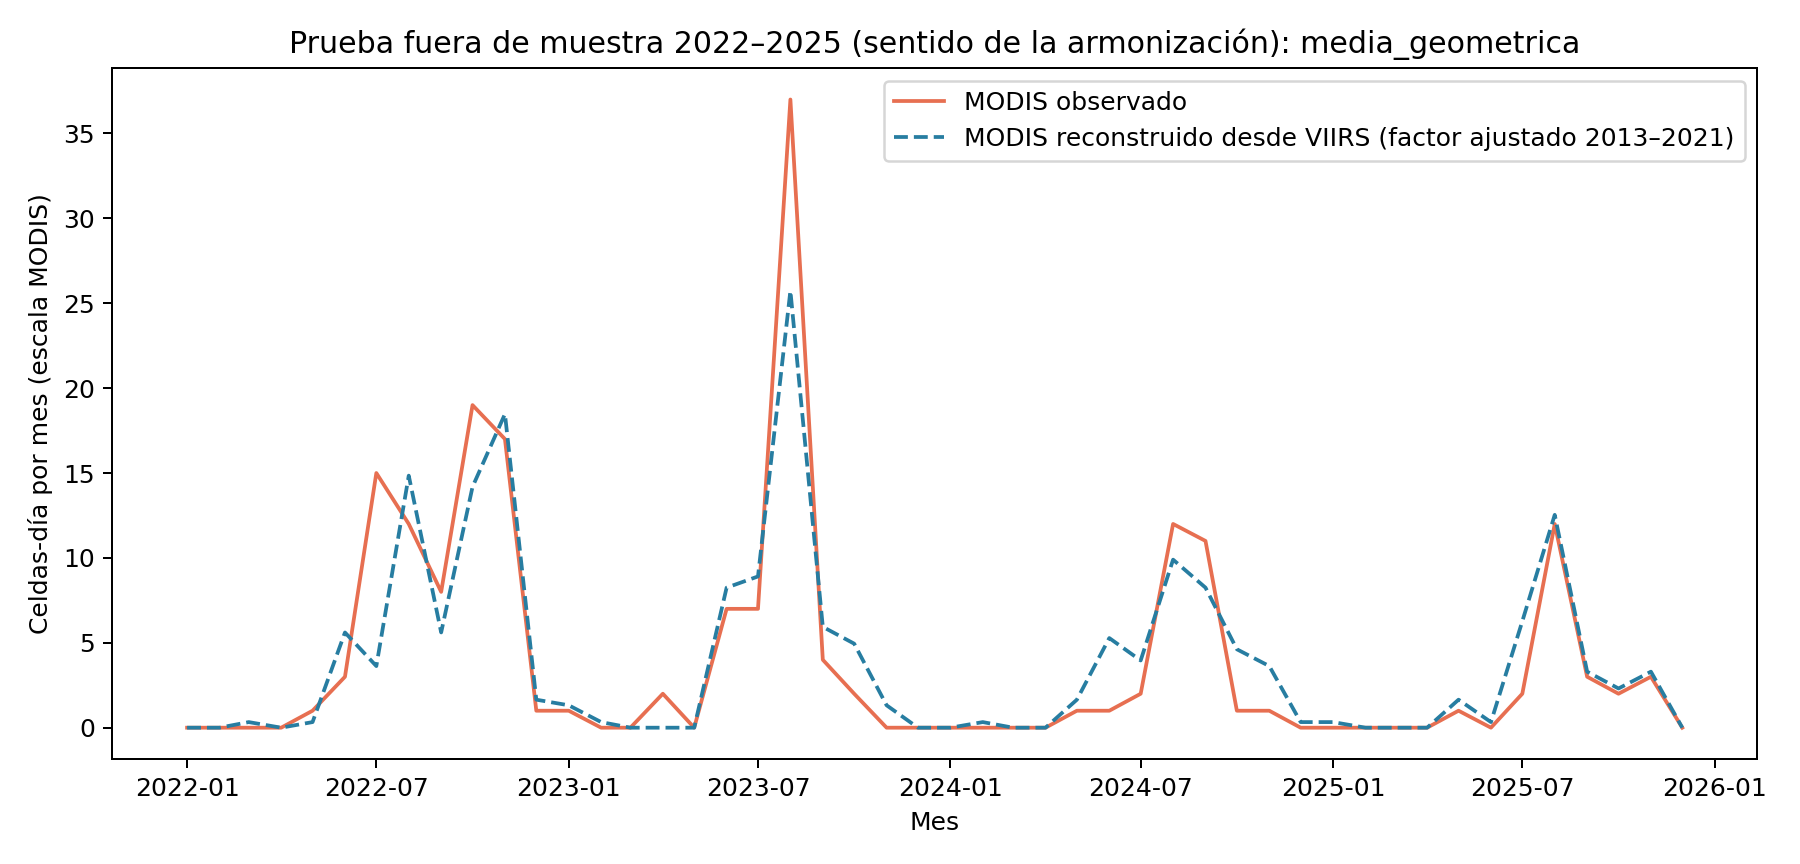

In [3]:
display(Image(filename=str(FIGURES / 'tunari_calibracion_prueba_2022_2025.png')))

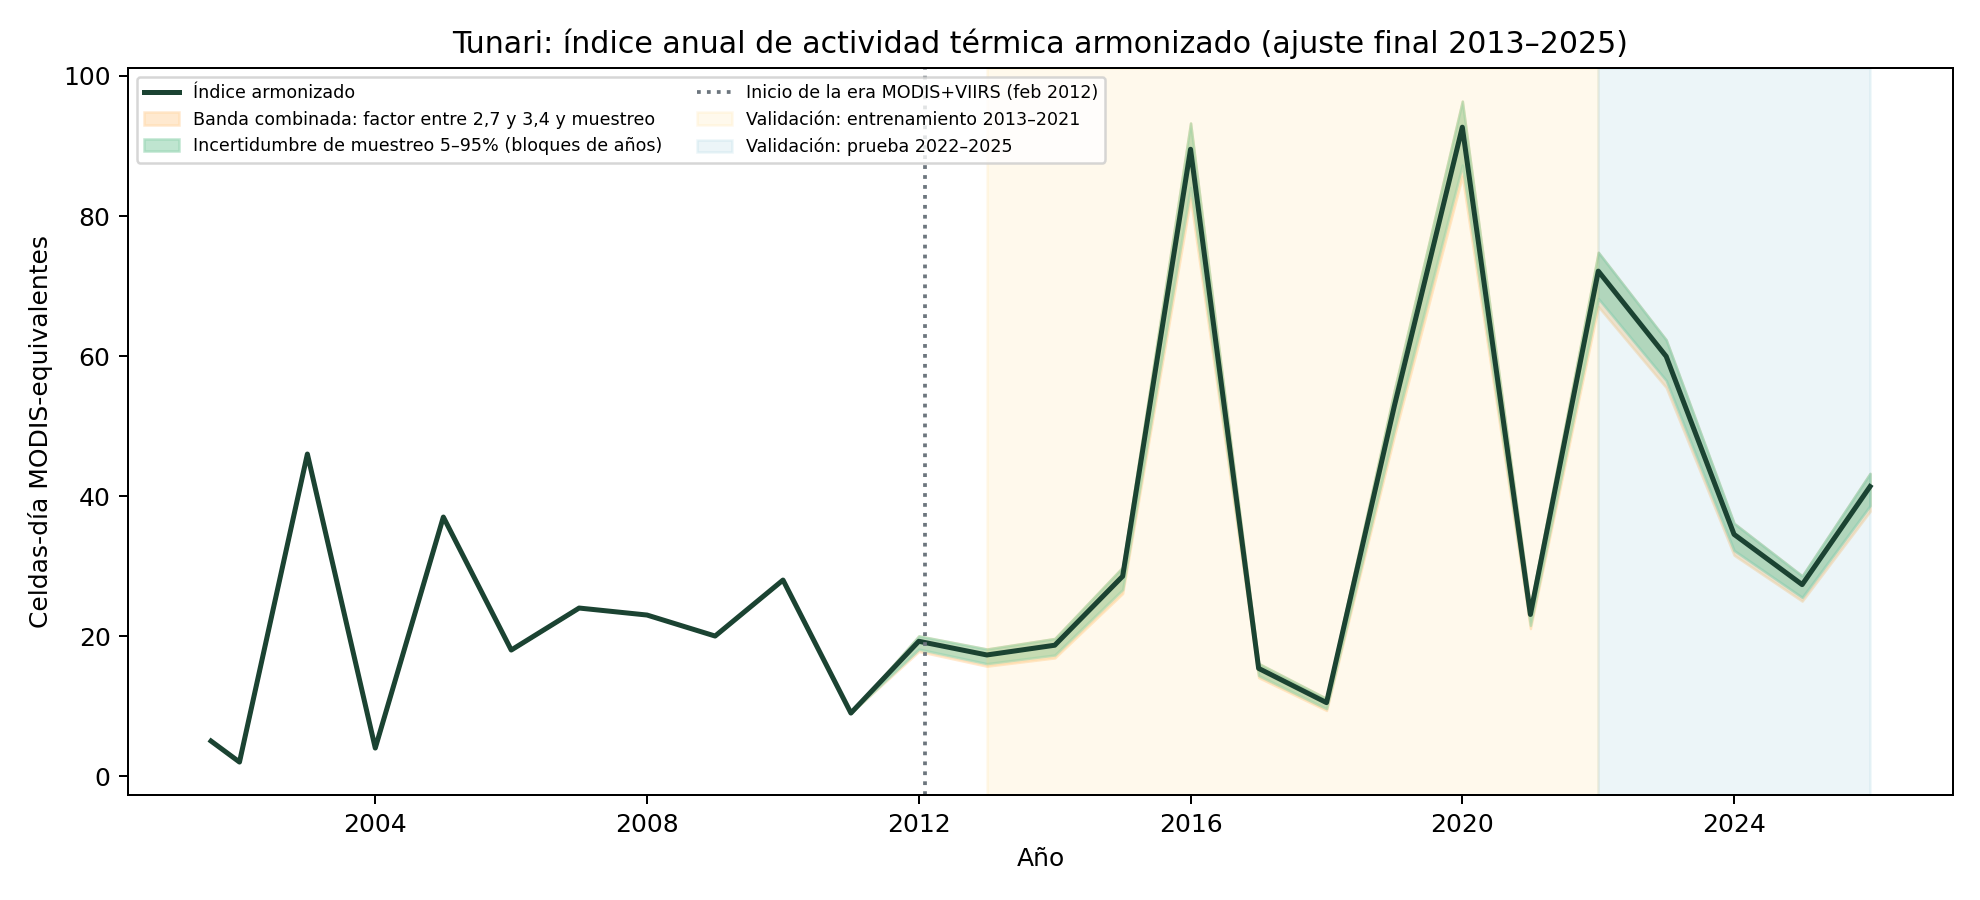

In [4]:
display(Image(filename=str(FIGURES / 'tunari_serie_anual_armonizada.png')))

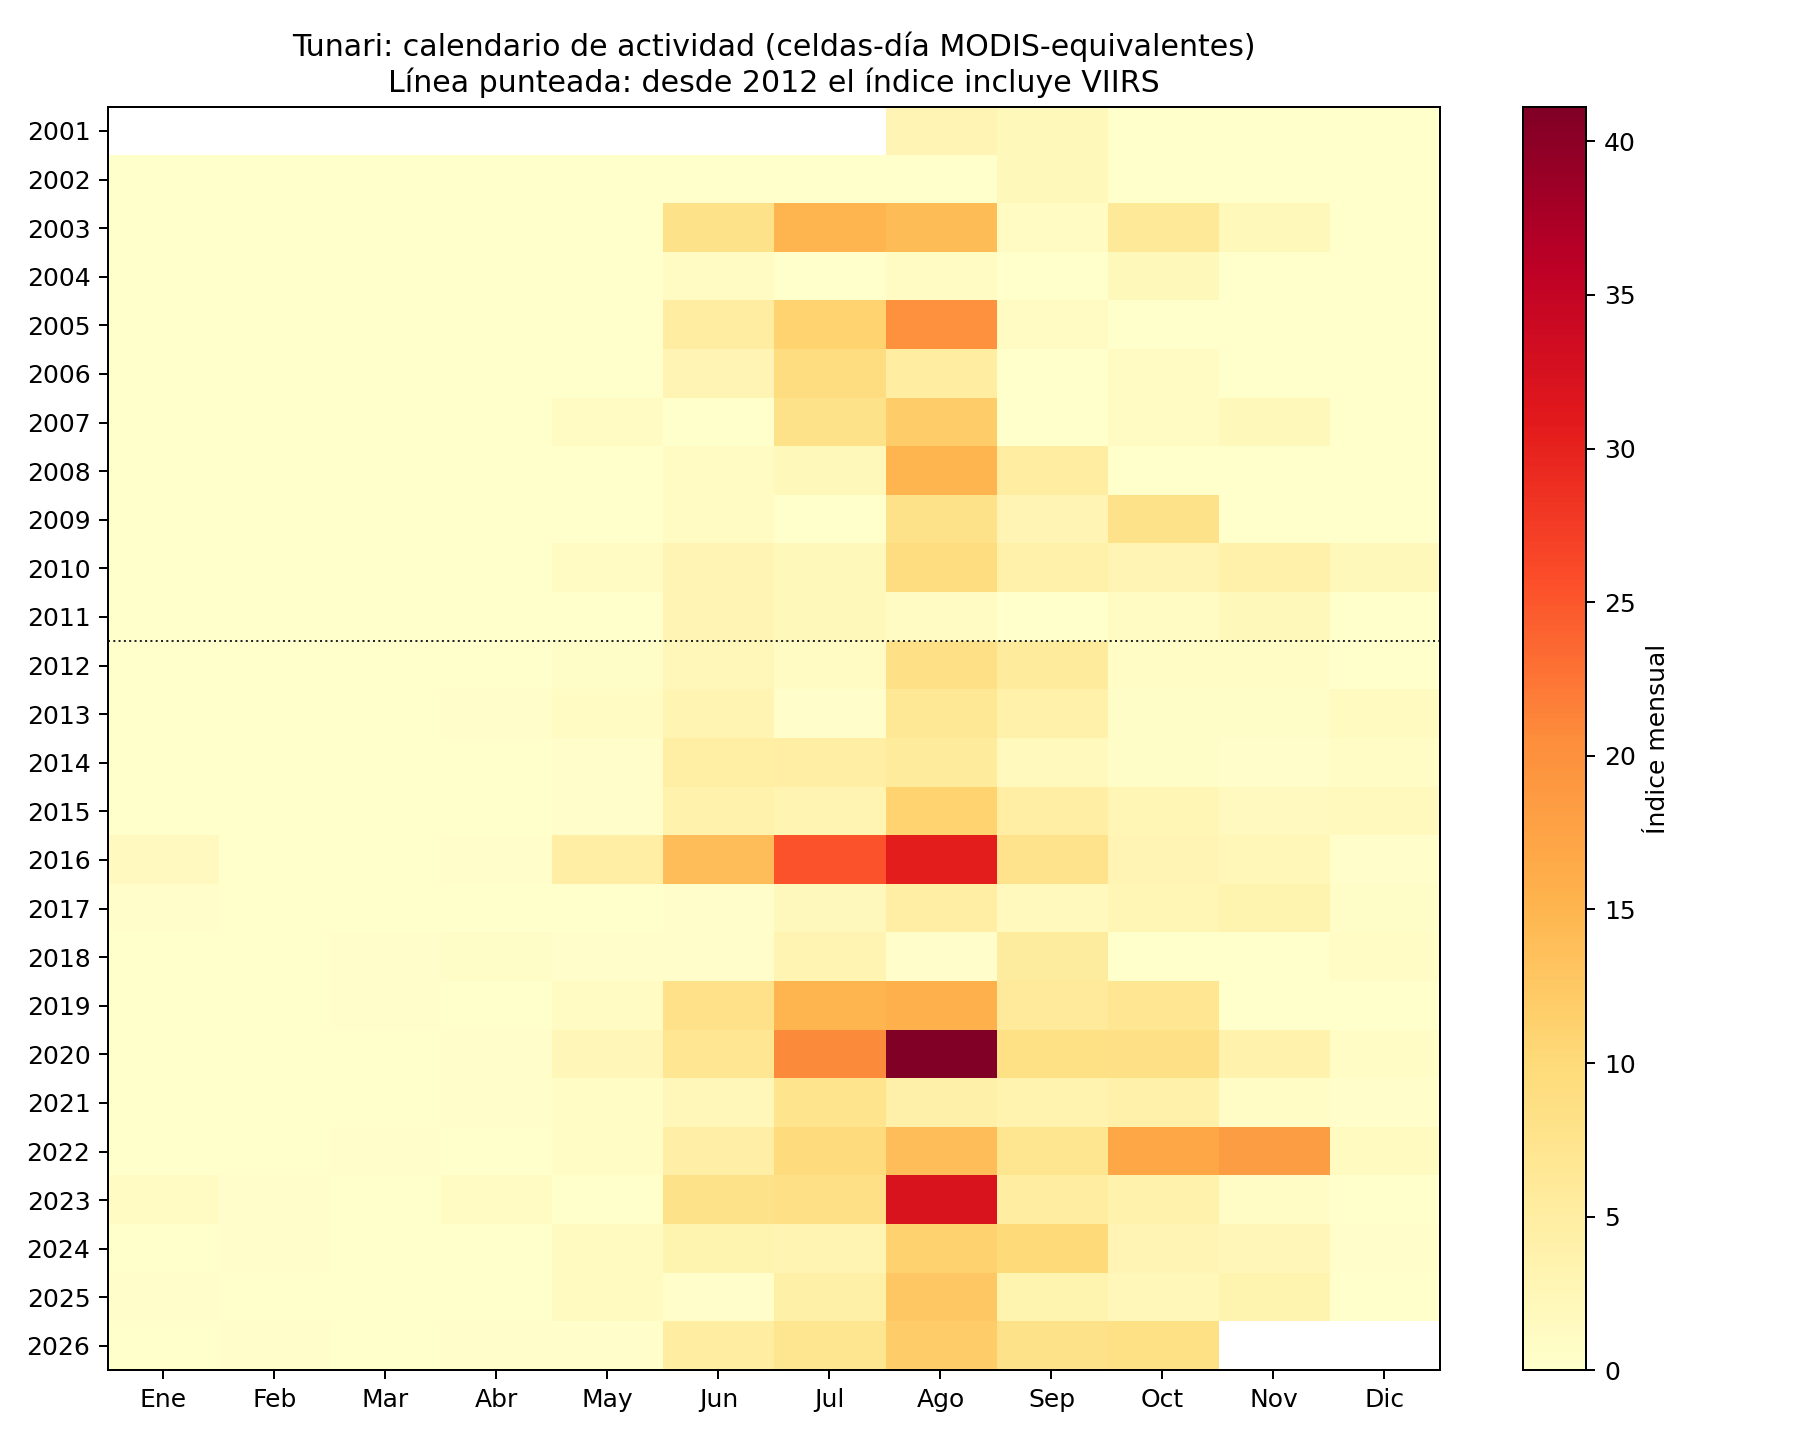

In [5]:
display(Image(filename=str(FIGURES / 'tunari_calendario_mes_anio.png')))

In [6]:
display(pd.read_csv(SERIES / 'tunari_sensibilidad_inclusion_2018.csv'))
display(pd.read_csv(SERIES / 'tunari_serie_anual_armonizada.csv').round(1).tail(8))
display(serie.tail(12))

,escenario,factor_global,modelo,metrica,n_meses_ajuste
0,incluye_2018_principal,2.871513,media_geometrica,celdas_dia,156
1,excluye_2018,2.860244,media_geometrica,celdas_dia,144


,periodo,mes_bo,meses_incluidos,indice,inferior,superior,inferior_estructural,superior_estructural
18,2019,2019-01-01,12,52.9,49.6,55.2,48.6,55.2
19,2020,2020-01-01,12,92.7,87.3,96.4,85.7,96.4
20,2021,2021-01-01,12,23.1,21.5,24.2,21.1,24.2
21,2022,2022-01-01,12,72.1,68.2,74.8,67.1,74.8
22,2023,2023-01-01,12,59.9,56.5,62.3,55.5,62.3
23,2024,2024-01-01,12,34.5,32.2,36.1,31.5,36.1
24,2025,2025-01-01,12,27.3,25.5,28.6,25.0,28.6
25,2026,2026-01-01,10,41.4,38.6,43.2,37.8,43.2


familia_calibracion,mes_bo,MODIS_TERRA_AQUA,VIIRS_SNPP,anio,mes,factor_viirs_por_modis,viirs_snpp_equivalente_modis,era,indice_actividad_modis_equivalente,fuentes_indice,indice_para_alertas,limite_inferior_estructural,limite_superior_estructural,limite_inferior_calibracion_p05,limite_superior_calibracion_p95,nota
291,2025-11-01,3.0,10.0,2025,11,2.871513,3.482485,MODIS+VIIRS-SNPP,3.241242,MODIS + VIIRS-SNPP calibrado,3.482485,2.982472,3.378483,3.041735,3.378483,Índice relativo en celdas-día MODIS-equivalent...
292,2025-12-01,0.0,0.0,2025,12,2.871513,0.000000,MODIS+VIIRS-SNPP,0.000000,MODIS + VIIRS-SNPP calibrado,0.000000,0.000000,0.000000,0.000000,0.000000,Índice relativo en celdas-día MODIS-equivalent...
293,2026-01-01,0.0,0.0,2026,1,2.871513,0.000000,MODIS+VIIRS-SNPP,0.000000,MODIS + VIIRS-SNPP calibrado,0.000000,0.000000,0.000000,0.000000,0.000000,Índice relativo en celdas-día MODIS-equivalent...
294,2026-02-01,0.0,1.0,2026,2,2.871513,0.348248,MODIS+VIIRS-SNPP,0.174124,MODIS + VIIRS-SNPP calibrado,0.348248,0.148247,0.187848,0.154173,0.187848,Índice relativo en celdas-día MODIS-equivalent...
295,2026-03-01,0.0,0.0,2026,3,2.871513,0.000000,MODIS+VIIRS-SNPP,0.000000,MODIS + VIIRS-SNPP calibrado,0.000000,0.000000,0.000000,0.000000,0.000000,Índice relativo en celdas-día MODIS-equivalent...
296,2026-04-01,0.0,2.0,2026,4,2.871513,0.696497,MODIS+VIIRS-SNPP,0.348248,MODIS + VIIRS-SNPP calibrado,0.696497,0.296494,0.375697,0.308347,0.375697,Índice relativo en celdas-día MODIS-equivalent...
297,2026-05-01,0.0,2.0,2026,5,2.871513,0.696497,MODIS+VIIRS-SNPP,0.348248,MODIS + VIIRS-SNPP calibrado,0.696497,0.296494,0.375697,0.308347,0.375697,Índice relativo en celdas-día MODIS-equivalent...
298,2026-06-01,5.0,14.0,2026,6,2.871513,4.875479,MODIS+VIIRS-SNPP,4.937739,MODIS + VIIRS-SNPP calibrado,4.875479,4.575460,5.129876,4.658429,5.129876,Índice relativo en celdas-día MODIS-equivalent...
299,2026-07-01,4.0,30.0,2026,7,2.871513,10.447454,MODIS+VIIRS-SNPP,7.223727,MODIS + VIIRS-SNPP calibrado,10.447454,6.447415,7.635449,6.625204,7.635449,Índice relativo en celdas-día MODIS-equivalent...
300,2026-08-01,10.0,39.0,2026,8,2.871513,13.581691,MODIS+VIIRS-SNPP,11.790845,MODIS + VIIRS-SNPP calibrado,13.581691,10.781640,12.326084,11.012765,12.326084,Índice relativo en celdas-día MODIS-equivalent...
